In [1]:
# ============================================================
# Cell 1. Imports, device, global settings (Uniform Dither Edition)
# ============================================================
# 理论公式更新 (Markdown 需同步修改):
# 均布噪声 \xi \sim U[-\sqrt{3}, \sqrt{3}]
# \bar h_m = \mathrm{clip}(u_m / \sqrt{3}, -1, 1)
# \tilde h_m = \partial\bar h_m/\partial\ln\sigma = -u_m / \sqrt{3} \quad (当 |u_m| \le \sqrt{3} 时), 否则为 0.

import json
import math
import os
import time

import numpy as np
import torch
import matplotlib
import matplotlib.pyplot as plt
from scipy import optimize, special, stats
from scipy.signal import lfilter

OUT_DIR = r"D:\IEEE 2025 Adaptive weighted SSR"
MASTER_SEED = 20261116
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DTYPE = torch.float64
torch.manual_seed(MASTER_SEED)
os.makedirs(OUT_DIR, exist_ok=True)

# ---- algorithm parameters ----
P0_W = 10.0          
PI0 = 1.0            
Q_SCALE = 1e-4       
LAM_STAT = 0.998     
TINY = 1e-300        

# ---- experiment sizes ----
N_EL = 31            
TRIALS = 100         
K_STAT = 12000       
BLOCK = 100          
DELTA = 0.10         
LATE = 4000          
N_BOOT = 500         
SIGMA0_LIST = (0.1, 0.5, 1.5, 4.0)

# 新增均布分布所需常数 SQRT3，移除高斯专用的 SQRT2PI
SQRT3 = math.sqrt(3.0)
SQRT2 = math.sqrt(2.0)
RES = {}             
SIG_RANGE = dict(lo=float("inf"), hi=0.0, runs=0, bad=0)   

def track_sigma(sig, sigma_o):
    r = np.asarray(sig) / sigma_o
    SIG_RANGE["lo"] = min(SIG_RANGE["lo"], float(np.nanmin(r)))
    SIG_RANGE["hi"] = max(SIG_RANGE["hi"], float(np.nanmax(r)))
    SIG_RANGE["runs"] += r.shape[0]
    SIG_RANGE["bad"] += int((~np.isfinite(r)).any(axis=1).sum())

def put(key, value, fmt="{:.3f}"):
    RES[key] = fmt.format(value) if not isinstance(value, str) else value
    return RES[key]

print(f"torch {torch.__version__}, device {DEVICE}, dtype {DTYPE}, Dither: UNIFORM")

torch 2.2.1, device cuda, dtype torch.float64, Dither: UNIFORM


In [2]:
# ============================================================
# Cell 2. Theory (Uniform Dither Edition)
# ============================================================
def law_gaussian(n=40001, span=10.0):
    x = np.linspace(-span, span, n)
    p = np.exp(-0.5 * x * x)
    p[[0, -1]] *= 0.5
    return x, p / p.sum()

def law_uniform(n=40001):
    x = np.linspace(-math.sqrt(3.0), math.sqrt(3.0), n)
    p = np.ones(n)
    p[[0, -1]] *= 0.5
    return x, p / p.sum()

# 核心重构 1：均布噪声的平均响应 hbar_m (带硬截断)
def hbar_np(x, sigma, th):
    u = (x[:, None] - th[None, :]) / sigma
    return np.clip(u / SQRT3, -1.0, 1.0)

# 核心重构 2：均布噪声的对数偏导 htil_m (边界外严格归零)
def htil_np(x, sigma, th):
    u = (x[:, None] - th[None, :]) / sigma
    valid = np.abs(u) <= SQRT3
    return np.where(valid, -u / SQRT3, 0.0)

def moments(sigma, law, thetas, Ns):
    x, pr = law
    th, Nm = np.asarray(thetas, float), np.asarray(Ns, float)
    h = hbar_np(x, sigma, th)
    Psi = (h * pr[:, None]).T @ h
    R = Psi + np.diag((1.0 - np.diag(Psi)) / Nm)
    m = pr @ h
    Rt = np.block([[np.ones((1, 1)), m[None, :]], [m[:, None], R]])
    pt = np.concatenate([[pr @ x], (pr * x) @ h])
    return pt, Rt, float(pr @ (x * x))

def wiener(sigma, law, thetas, Ns):
    pt, Rt, power = moments(sigma, law, thetas, Ns)
    w = np.linalg.solve(Rt, pt)
    return power - float(pt @ w), w

SIG_GRID = np.geomspace(0.02, 8.0, 260)

def sigma_opt(law, thetas, Ns):
    v = np.array([wiener(s, law, thetas, Ns)[0] for s in SIG_GRID])
    n_loc = int(np.sum((v[1:-1] < v[:-2]) & (v[1:-1] < v[2:])))
    i = int(np.argmin(v))
    lo, hi = SIG_GRID[max(i - 1, 0)], SIG_GRID[min(i + 1, SIG_GRID.size - 1)]
    res = optimize.minimize_scalar(lambda s: wiener(s, law, thetas, Ns)[0], bounds=(lo, hi),
                                   method="bounded", options={"xatol": 1e-10})
    return float(res.x), n_loc

def reference(law, thetas, Ns):
    s_o, n_loc = sigma_opt(law, thetas, Ns)
    z_o, w_o = wiener(s_o, law, thetas, Ns)
    out = dict(sigma_o=s_o, zeta_o=z_o, w_o=w_o, n_local_min=n_loc,
               zeta_0=wiener(SIG_GRID[0], law, thetas, Ns)[0])
    return out

In [3]:
# ============================================================
# Cell 3. Reference values (Gaussian Input, Uniform Dither)
# ============================================================
LAW_G = law_gaussian()

# 移除了高斯专用的 zeta_cf(s, N) 闭式解测试，直接输出均布噪声下高斯信号的最优靶心
SMALL_N = {}
print("M = 1, theta = 0, Gaussian input with UNIFORM dither:  N   sigma^o  zeta(sigma^o)  w^o")
for N in (2, 3, 5, 10, 31):
    r = reference(LAW_G, (0.0,), (N,))
    SMALL_N[N] = r
    print(f"{N:56d}  {r['sigma_o']:.4f}   {r['zeta_o']:.4f}      {r['w_o'][1]:.4f}")
    put(f"N{N}.sigo", r["sigma_o"]); put(f"N{N}.zo", r["zeta_o"]); put(f"N{N}.wo", r["w_o"][1])

ZETA_NOISEFREE = 1.0 - 2.0 / math.pi
put("zeta0", ZETA_NOISEFREE)
print(f"noise-free MSE 1 - 2/pi = {ZETA_NOISEFREE:.4f}")

M = 1, theta = 0, Gaussian input with UNIFORM dither:  N   sigma^o  zeta(sigma^o)  w^o
                                                       2  0.2519   0.3252      0.8727
                                                       3  0.3672   0.2871      0.9540
                                                       5  0.4974   0.2361      1.0770
                                                      10  0.6583   0.1714      1.2669
                                                      31  0.8971   0.0909      1.6056
noise-free MSE 1 - 2/pi = 0.3634


In [4]:
# ============================================================
# Cell 4. PyTorch simulator (Uniform Dither Edition)
# ============================================================
LOG_CLIP = 1.0       

def dither_to_device(xi):
    return torch.as_tensor(np.ascontiguousarray(np.transpose(xi, (1, 0, 2))), dtype=torch.float32, device=DEVICE)

def _rows(v, B):
    return torch.as_tensor(np.broadcast_to(np.asarray(v, dtype=np.float64), (B,)).copy(), dtype=DTYPE, device=DEVICE)

@torch.no_grad()
def simulate(x, xi_t, thetas, Ns, rule="ekf", sigma0=1.0, lam_f=1.0, q=Q_SCALE, Pi0=PI0, mu=0.0,
             P0=P0_W, corrected=True, w_init=None, x_idx=None, xi_idx=None,
             rec_err=True, rec_sigma=False, rec_w=False, seg_bounds=None):
    
    x = np.atleast_2d(np.asarray(x, dtype=np.float64))
    S, K = x.shape
    if x_idx is None:
        x_idx = np.arange(S)
    x_idx = np.asarray(x_idx)
    xi_idx = x_idx if xi_idx is None else np.asarray(xi_idx)
    B, M = x_idx.size, len(Ns)
    D = M + 1
    xs = torch.as_tensor(np.ascontiguousarray(x.T), dtype=DTYPE, device=DEVICE)        
    xr = torch.as_tensor(x_idx, dtype=torch.long, device=DEVICE)
    ir = torch.as_tensor(xi_idx, dtype=torch.long, device=DEVICE)

    gavg = np.zeros((int(sum(Ns)), M))
    a = 0
    for m, n_m in enumerate(Ns):
        gavg[a:a + n_m, m] = 1.0 / n_m
        a += n_m
    Gavg = torch.as_tensor(gavg, dtype=DTYPE, device=DEVICE)
    th_el = torch.as_tensor(np.repeat(np.asarray(thetas, float), Ns), dtype=DTYPE, device=DEVICE)
    th_g = torch.as_tensor(np.asarray(thetas, float), dtype=DTYPE, device=DEVICE)
    Nm = torch.as_tensor(np.asarray(Ns, float), dtype=DTYPE, device=DEVICE)

    lam, q_b, mu_b = _rows(lam_f, B), _rows(q, B), _rows(mu, B)
    sigma = _rows(sigma0, B)
    rho = torch.log(sigma)
    if w_init is None:
        w = torch.zeros((B, D), dtype=DTYPE, device=DEVICE)
    else:
        w = torch.as_tensor(np.broadcast_to(np.asarray(w_init, float), (B, D)).copy(), dtype=DTYPE, device=DEVICE)
    P = torch.eye(D, dtype=DTYPE, device=DEVICE).unsqueeze(0).expand(B, D, D).clone() * P0
    Pi = torch.full((B,), float(Pi0), dtype=DTYPE, device=DEVICE)
    zh = torch.zeros((B,), dtype=DTYPE, device=DEVICE)
    one = torch.ones((B, 1), dtype=DTYPE, device=DEVICE)

    err_t = torch.empty((K, B), dtype=DTYPE, device=DEVICE) if rec_err else None
    sig_t = torch.empty((K, B), dtype=DTYPE, device=DEVICE) if rec_sigma else None
    w_t = torch.empty((K, B, D), dtype=DTYPE, device=DEVICE) if rec_w else None
    
    seg_of = np.full(K, -1)
    if seg_bounds is not None:
        for j, (sa, sb) in enumerate(seg_bounds):
            seg_of[sa:sb] = j
        seg_err = torch.zeros((len(seg_bounds), B), dtype=DTYPE, device=DEVICE)
        seg_pow = torch.zeros((len(seg_bounds), B), dtype=DTYPE, device=DEVICE)

    for k in range(K):
        xk = xs[k][xr]
        xik = xi_t[k][ir].to(DTYPE)
        
        # Array output calculation
        s = torch.sign(xk[:, None] + sigma[:, None] * xik - th_el) @ Gavg           
        st = torch.cat([one, s], dim=1)                                             
        eps = xk - (w * st).sum(-1)                                                 
        
        if rec_err: err_t[k] = eps
        if rec_sigma: sig_t[k] = sigma
        if seg_of[k] >= 0:
            seg_err[seg_of[k]] += eps * eps
            seg_pow[seg_of[k]] += xk * xk
        if rule == "genie":
            if rec_w: w_t[k] = w
            continue

        # RLS weight update
        Ps = (P @ st[:, :, None])[:, :, 0]
        g = Ps / ((st * Ps).sum(-1) + lam)[:, None]
        w_prev = w
        w = w + g * eps[:, None]
        P = (P - g[:, :, None] * Ps[:, None, :]) / lam[:, None, None]
        P = 0.5 * (P + P.transpose(1, 2))
        if rec_w: w_t[k] = w
        if rule == "fixed": continue

        # ---- 核心重构 3: 均布噪声 Scale update on ln(sigma) ----
        u = (xk[:, None] - th_g) / sigma[:, None]
        
        hb = torch.clamp(u / SQRT3, min=-1.0, max=1.0)              # hbar_m (Uniform)
        valid_zone = torch.abs(u) <= SQRT3                          # EKF 死区判断
        ht = torch.where(valid_zone, -u / SQRT3, torch.zeros_like(u)) # d hbar_m / d ln(sigma)
        
        wg = w_prev[:, 1:]
        G = (wg * ht).sum(-1)                                       
        d = G * eps
        if corrected:
            d = d + (wg * wg / Nm * hb * ht).sum(-1)                
            
        beta = torch.clamp(1.0 - lam, min=1.0 / (k + 1.0))
        zh = (1.0 - beta) * zh + beta * eps * eps                   
        
        if rule == "ekf":
            den = G * G * Pi + zh
            kap = torch.where(den > 0.0, Pi / torch.clamp(den, min=TINY), torch.zeros_like(den))
            Pi = (1.0 - kap * G * G) * Pi + q_b
            step = kap * d
        elif rule == "grad":
            step = torch.clamp(mu_b * d / (sigma * sigma), min=-LOG_CLIP, max=LOG_CLIP)
        elif rule == "ngrad":
            den = mu_b * G * G + zh
            step = torch.where(den > 0.0, mu_b * d / torch.clamp(den, min=TINY), torch.zeros_like(den))
            step = torch.clamp(step, min=-LOG_CLIP, max=LOG_CLIP)
            
        rho = rho + step
        sigma = torch.exp(rho)

    out = dict(err=None if err_t is None else err_t.transpose(0, 1).cpu().numpy(),
               sigma=None if sig_t is None else sig_t.transpose(0, 1).cpu().numpy(),
               w=None if w_t is None else w_t.transpose(0, 1).cpu().numpy(),
               sigma_final=sigma.cpu().numpy())
    if seg_bounds is not None:
        out["seg_err"] = seg_err.transpose(0, 1).cpu().numpy()
        out["seg_pow"] = seg_pow.transpose(0, 1).cpu().numpy()
    return out

In [5]:
# ============================================================
# Cell 5. Random streams (Uniform Dither Injection)
# ============================================================
def child_rngs(tag, n):
    return [np.random.default_rng(c) for c in np.random.SeedSequence([MASTER_SEED, tag]).spawn(n)]

def synth_vowel(K, fs=8000, F0=120.0, harmonics=25, formants=((800.0, 80.0), (1200.0, 100.0), (2500.0, 150.0))):
    t = np.arange(K) / fs
    src = np.zeros(K)
    for h in range(1, harmonics + 1):
        src += np.sin(2.0 * np.pi * h * F0 * t) / h
    y = src
    for fc, bw in formants:
        r = math.exp(-math.pi * bw / fs)
        th = 2.0 * math.pi * fc / fs
        y = lfilter([1.0 - r], [1.0, -2.0 * r * math.cos(th), r * r], y)
    return y / math.sqrt(np.mean(y * y))

def make_streams(kind, L, K, N, tag):
    xs, xis = [], []
    for r in child_rngs(tag, L):
        # 信号生成逻辑不变
        if kind == "gauss":
            xs.append(r.standard_normal(K))
        elif kind == "laplace":
            xs.append(r.laplace(0.0, 1.0 / SQRT2, K))
        elif kind == "uniform":
            xs.append(r.uniform(-math.sqrt(3.0), math.sqrt(3.0), K))
        elif kind == "sine":
            xs.append(SQRT2 * np.sin(r.uniform(0.0, 2.0 * np.pi, K)))
        elif kind == "vowel":
            xs.append(synth_vowel(K))
        
        # 核心重构 4: 将阵列注入的抖动噪声彻底改为 均布分布
        xis.append(r.uniform(-math.sqrt(3.0), math.sqrt(3.0), (K, N)).astype(np.float32))
        
    return np.stack(xs), np.stack(xis)

def excess_curve(bs, bs_ref):
    return bs.sum(0) / bs_ref.sum(0) - 1.0

def settling_time(E, W, delta):
    bad = np.flatnonzero(E > delta)
    if bad.size == 0: return 0.0
    return float("inf") if bad[-1] == E.size - 1 else float((bad[-1] + 1) * W)

def convergence_metrics(err, err_ref, sigma, W=BLOCK, delta=DELTA, late=LATE, n_boot=N_BOOT, tag=900):
    L, K = err.shape
    J = K // W
    bs = (err[:, :J * W] ** 2).reshape(L, J, W).sum(-1)
    bs_ref = (err_ref[:, :J * W] ** 2).reshape(L, J, W).sum(-1)
    E = excess_curve(bs, bs_ref)
    jl = late // W
    mis = bs[:, -jl:].sum() / bs_ref[:, -jl:].sum() - 1.0
    rng = np.random.default_rng([MASTER_SEED, tag])
    Tb, Mb = [], []
    for _ in range(n_boot):
        i = rng.integers(0, L, L)
        Tb.append(min(settling_time(excess_curve(bs[i], bs_ref[i]), W, delta), K + W))
        Mb.append(bs[i][:, -jl:].sum() / bs_ref[i][:, -jl:].sum() - 1.0)
    sig_late = sigma[:, -late:].mean(1)
    q_lo, q_hi = np.percentile(Tb, [2.5, 97.5], method="nearest")
    return dict(curve=E, T=settling_time(E, W, delta),
                T_lo=float(q_lo) if q_lo <= K else float("inf"), T_hi=float(q_hi) if q_hi <= K else float("inf"),
                misadj=float(mis), misadj_se=float(np.std(Mb, ddof=1)),
                mse_late=float(bs[:, -jl:].sum() / (L * jl * W)),
                sig_mean=float(sig_late.mean()), sig_sd=float(sig_late.std(ddof=1)))

def fmt_T(T):
    return r"$>\!K$" if not np.isfinite(T) else f"${int(round(T))}$"

In [6]:
# ============================================================
# Cell 6. Experiment A (Execution with Uniform Dither)
# ============================================================
t0 = time.time()
TH1, NS1 = (0.0,), (N_EL,)
REF1 = reference(LAW_G, TH1, NS1)
xA, xiA = make_streams("gauss", TRIALS, K_STAT, N_EL, tag=1)
xiA_t = dither_to_device(xiA)
n0 = len(SIGMA0_LIST)
rowsA = np.tile(np.arange(TRIALS), n0)

outA = simulate(xA, xiA_t, TH1, NS1, "ekf", sigma0=np.repeat(SIGMA0_LIST, TRIALS), x_idx=rowsA,
                lam_f=LAM_STAT, rec_sigma=True, rec_w=True)
genieA = simulate(xA, xiA_t, TH1, NS1, "genie", sigma0=REF1["sigma_o"], w_init=REF1["w_o"])
track_sigma(outA["sigma"], REF1["sigma_o"])

MET_A = {}
for i, s0 in enumerate(SIGMA0_LIST):
    sl = slice(i * TRIALS, (i + 1) * TRIALS)
    MET_A[s0] = convergence_metrics(outA["err"][sl], genieA["err"], outA["sigma"][sl], tag=900 + i)
    MET_A[s0]["sigma_traj"] = outA["sigma"][sl]
    MET_A[s0]["w_traj"] = outA["w"][sl][:, :, 1]
    m = MET_A[s0]
    print(f"sigma0 = {s0:3.1f}: sigma_late = {m['sig_mean']:.3f} +- {m['sig_sd']:.3f} (sigma^o = {REF1['sigma_o']:.3f}), "
          f"misadjustment = {100 * m['misadj']:.1f}% (SE {100 * m['misadj_se']:.1f}), "
          f"T = {m['T']:.0f} [{m['T_lo']:.0f}, {m['T_hi']:.0f}]")

genie_ratio = float((genieA["err"] ** 2).mean() / REF1["zeta_o"])
print(f"genie array: simulated MSE / zeta^min(sigma^o) = {genie_ratio:.4f}")

outA1 = simulate(xA, xiA_t, TH1, NS1, "ekf", sigma0=np.repeat(SIGMA0_LIST, TRIALS), x_idx=rowsA,
                 lam_f=1.0, rec_sigma=True)
sigA1 = [outA1["sigma"][i * TRIALS:(i + 1) * TRIALS, -LATE:].mean() for i in range(n0)]
misA1 = [100 * ((outA1["err"][i * TRIALS:(i + 1) * TRIALS, -LATE:] ** 2).sum() / (genieA["err"][:, -LATE:] ** 2).sum() - 1)
         for i in range(n0)]
print("lambda_f = 1: sigma_late = " + ", ".join(f"{v:.3f}" for v in sigA1)
      + "; misadjustment (%) = " + ", ".join(f"{v:.1f}" for v in misA1))

del outA1, xiA_t, xiA
print(f"Experiment A: {time.time() - t0:.1f} s")

sigma0 = 0.1: sigma_late = 0.895 +- 0.011 (sigma^o = 0.897), misadjustment = 0.8% (SE 0.0), T = 1000 [900, 1000]
sigma0 = 0.5: sigma_late = 0.896 +- 0.011 (sigma^o = 0.897), misadjustment = 0.8% (SE 0.0), T = 200 [100, 300]
sigma0 = 1.5: sigma_late = 0.896 +- 0.011 (sigma^o = 0.897), misadjustment = 0.8% (SE 0.0), T = 100 [100, 100]
sigma0 = 4.0: sigma_late = 0.896 +- 0.011 (sigma^o = 0.897), misadjustment = 0.8% (SE 0.0), T = 300 [200, 300]
genie array: simulated MSE / zeta^min(sigma^o) = 1.0007
lambda_f = 1: sigma_late = 0.825, 0.874, 0.904, 0.923; misadjustment (%) = 3.3, 0.9, 0.7, 1.1
Experiment A: 30.4 s


In [7]:
# ============================================================
# Cell 7. Experiment B (Table I): Stationary performance vs. N
#         (Gaussian Input, Uniform Dither)
# ============================================================
t0 = time.time()
N_LIST = (2, 3, 5, 10, 31)
MET_B = {}

print("Experiment B (Table I): Stationary tracking with UNIFORM dither")
print(" N | sigma_late (mean +- SD) | sigma^o | misadj(%) | T")
print("-" * 65)

for i, n_el in enumerate(N_LIST):
    th_b, ns_b = (0.0,), (n_el,)
    # 这里会自动调用 Cell 2 中重构的均布 reference 函数
    ref_b = reference(LAW_G, th_b, ns_b)
    
    # make_streams 在 Cell 5 中已修改，xiB 内部即为均布噪声
    xB, xiB = make_streams("gauss", TRIALS, K_STAT, n_el, tag=20+i)
    xiB_t = dither_to_device(xiB)
    
    # 运行 RLS-EKF 在线仿真
    outB = simulate(xB, xiB_t, th_b, ns_b, "ekf", sigma0=1.0, 
                    lam_f=LAM_STAT, rec_sigma=True)
    # 运行 Genie 上界基准
    genieB = simulate(xB, xiB_t, th_b, ns_b, "genie", 
                      sigma0=ref_b["sigma_o"], w_init=ref_b["w_o"])
    
    track_sigma(outB["sigma"], ref_b["sigma_o"])
    
    # 计算收敛指标
    m = convergence_metrics(outB["err"], genieB["err"], outB["sigma"], tag=800+i)
    MET_B[n_el] = m
    
    print(f"{n_el:2d} | {m['sig_mean']:.4f} +- {m['sig_sd']:.4f} | {ref_b['sigma_o']:.4f} | "
          f"{100 * m['misadj']:5.2f}     | {m['T']:.0f} [{m['T_lo']:.0f}, {m['T_hi']:.0f}]")
    
    # 写入结果字典以备 LaTeX 导出
    tagk = f"B.N{n_el}"
    put(tagk + ".Tlo", fmt_T(m["T_lo"]).strip("$")); put(tagk + ".Thi", fmt_T(m["T_hi"]).strip("$"))
    put(tagk + ".sig", m["sig_mean"]); put(tagk + ".sd", m["sig_sd"])
    put(tagk + ".mis", 100 * m["misadj"], "{:.1f}"); put(tagk + ".T", fmt_T(m["T"]).strip("$"))
    
    del xiB_t, xiB, outB, genieB

put("B.mismax", 100 * max(MET_B[n]["misadj"] for n in N_LIST), "{:.1f}")
put("B.mismin", 100 * min(MET_B[n]["misadj"] for n in N_LIST), "{:.1f}")
print("-" * 65)
print(f"Experiment B completed in {time.time() - t0:.1f} s")

Experiment B (Table I): Stationary tracking with UNIFORM dither
 N | sigma_late (mean +- SD) | sigma^o | misadj(%) | T
-----------------------------------------------------------------
 2 | 0.2505 +- 0.0119 | 0.2519 |  0.33     | 100 [100, 100]
 3 | 0.3650 +- 0.0089 | 0.3672 |  0.34     | 100 [100, 100]
 5 | 0.4972 +- 0.0087 | 0.4974 |  0.42     | 100 [100, 100]
10 | 0.6578 +- 0.0093 | 0.6583 |  0.47     | 100 [100, 100]
31 | 0.8941 +- 0.0106 | 0.8971 |  0.84     | 100 [100, 100]
-----------------------------------------------------------------
Experiment B completed in 80.4 s


In [8]:
# ============================================================
# Cell 8. Generate LaTeX code for Table I
# ============================================================
def make_table1():
    lines = [
        r"\begin{table}[t]",
        r"\centering",
        r"\caption{Steady-state performance versus array size $N$}",
        r"\label{tab:stat}",
        r"\begin{tabular}{rccccc}",
        r"\toprule",
        r"$N$ & $\sigma^o$ & $\zeta^{\min}(\sigma^o)$ & $\sigma_k$ late avg. & $\eta$ (\%) & $T$ \\",
        r"\midrule"
    ]
    for n_el in N_LIST:
        r_ref = SMALL_N[n_el]
        m = MET_B[n_el]
        sig_str = f"${m['sig_mean']:.3f} \\pm {m['sig_sd']:.3f}$"
        T_str = fmt_T(m['T'])
        lines.append(f"{n_el:2d} & ${r_ref['sigma_o']:.3f}$ & ${r_ref['zeta_o']:.3f}$ & {sig_str} & "
                     f"${100 * m['misadj']:.1f}$ & {T_str} \\\\")
    lines.extend([
        r"\bottomrule",
        r"\end{tabular}",
        r"\end{table}"
    ])
    
    tex_code = "\n".join(lines)
    with open(os.path.join(OUT_DIR, "table1.tex"), "w") as f:
        f.write(tex_code)
    print("Table I LaTeX code saved to OUT_DIR:")
    print(tex_code)

make_table1()

Table I LaTeX code saved to OUT_DIR:
\begin{table}[t]
\centering
\caption{Steady-state performance versus array size $N$}
\label{tab:stat}
\begin{tabular}{rccccc}
\toprule
$N$ & $\sigma^o$ & $\zeta^{\min}(\sigma^o)$ & $\sigma_k$ late avg. & $\eta$ (\%) & $T$ \\
\midrule
 2 & $0.252$ & $0.325$ & $0.251 \pm 0.012$ & $0.3$ & $100$ \\
 3 & $0.367$ & $0.287$ & $0.365 \pm 0.009$ & $0.3$ & $100$ \\
 5 & $0.497$ & $0.236$ & $0.497 \pm 0.009$ & $0.4$ & $100$ \\
10 & $0.658$ & $0.171$ & $0.658 \pm 0.009$ & $0.5$ & $100$ \\
31 & $0.897$ & $0.091$ & $0.894 \pm 0.011$ & $0.8$ & $100$ \\
\bottomrule
\end{tabular}
\end{table}


In [10]:
# ============================================================
# Cell 9. Experiment C: Grid search (Tune) on development streams
#         (Gaussian Input, Uniform Dither) - WITH PROGRESS TRACKING
# ============================================================
import sys
t0 = time.time()

# ---- 1. 定义实验尺寸与幅度跳变 (验证集 A_DEV) ----
A_DEV = (0.1, 0.2, 1.0/3.0, 3.0, 5.0, 10.0)
K_WARMUP_C = 1000
K_ONLINE_C = 3000
K_TOTAL_C = K_WARMUP_C + K_ONLINE_C
JUMP_AT = 1500  # 在线阶段的第1500步发生跳变

LAM_GRID = (0.93, 0.95, 0.97)
METHODS_TUNE = {
    "RLS--EKF":            dict(rule="ekf",   pi="q",      p_grid=np.geomspace(1e-4, 1e-1, 13)),
    "Normalized gradient": dict(rule="ngrad", pi="mu",     p_grid=np.geomspace(1e-3, 1e0, 13)),
    "Gradient":            dict(rule="grad",  pi="mu",     p_grid=np.geomspace(1e-2, 1e1, 13)),
    "Fixed scale":         dict(rule="fixed", pi="sigma0", p_grid=np.geomspace(0.1, 2.0, 20)),
}

# ---- 2. 生成 Development Streams ----
L_DEV = 60  # 60次蒙特卡洛平均用于调参足够稳定
dev_x_full = {}
dev_xi_t = {}

print("Generating development streams for Uniform Dither...")
for A in A_DEV:
    x, xi = make_streams("gauss", L_DEV, K_TOTAL_C, N_EL, tag=100 + int(A * 100))
    x[:, K_WARMUP_C + JUMP_AT:] *= A
    dev_x_full[A] = x
    dev_xi_t[A] = dither_to_device(xi)
print("Streams generated. Starting Grid Search (this may take 5-10 minutes)...\n")

# ---- 3. 网格搜索核心逻辑 (带实时进度打印) ----
def tune_method(method_name):
    rule = METHODS_TUNE[method_name]["rule"]
    pi_name = METHODS_TUNE[method_name]["pi"]
    p_grid = METHODS_TUNE[method_name]["p_grid"]
    
    best_crit = float("inf")
    best_p, best_lam = None, None
    
    total_iters = len(LAM_GRID) * len(p_grid)
    current_iter = 0
    
    for lam in LAM_GRID:
        for p in p_grid:
            current_iter += 1
            # 实时覆盖打印进度，防止刷屏
            sys.stdout.write(f"\r  [{current_iter:3d}/{total_iters:3d}] Tuning {method_name:19s} | {pi_name} = {p:.5g}, lam_f = {lam:.2f}")
            sys.stdout.flush()
            
            crit_sum = 0.0
            for A in A_DEV:
                kw = {"rule": rule, "lam_f": lam, "sigma0": 1.0}
                if rule == "fixed":
                    kw["sigma0"] = p
                else:
                    kw[pi_name] = p
                
                res = simulate(dev_x_full[A], dev_xi_t[A], TH1, NS1, rec_err=True, rec_sigma=False, **kw)
                
                # 计算跳变后 (Post-change) 的 NMSE
                err_post = res["err"][:, K_WARMUP_C + JUMP_AT:]
                nmse = (err_post**2).mean() / (A**2)
                crit_sum += nmse
            
            avg_crit = crit_sum / len(A_DEV)
            if avg_crit < best_crit:
                best_crit = avg_crit
                best_p, best_lam = p, lam
                
    sys.stdout.write(f"\r  [DONE] Tuning {method_name:23s} | Best: {pi_name} = {best_p:.5g}, lam_f = {best_lam:.2f} (NMSE {best_crit:.4f})\n")
    sys.stdout.flush()
    return best_p, best_lam, best_crit

# ---- 4. 执行调参并保存结果 ----
BEST_PARAMS = {}
for m in METHODS_TUNE:
    p, lam, crit = tune_method(m)
    BEST_PARAMS[m] = {METHODS_TUNE[m]["pi"]: p, "lam_f": lam, "rule": METHODS_TUNE[m]["rule"]}
    if METHODS_TUNE[m]["rule"] != "fixed":
        BEST_PARAMS[m]["sigma0"] = 1.0

print(f"\nAll tuning completed in {time.time() - t0:.1f} s")

Generating development streams for Uniform Dither...
Streams generated. Starting Grid Search (this may take 5-10 minutes)...

  [DONE] Tuning RLS--EKF                | Best: q = 0.01, lam_f = 0.93 (NMSE 0.1474)
  [DONE] Tuning Normalized gradient     | Best: mu = 0.1, lam_f = 0.93 (NMSE 0.1561)
  [DONE] Tuning Gradient                | Best: mu = 0.31623, lam_f = 0.93 (NMSE 0.2267)
  [DONE] Tuning Fixed scale             | Best: sigma0 = 0.16048, lam_f = 0.93 (NMSE 0.2871)

All tuning completed in 3591.2 s


In [13]:
# ============================================================
# Cell 10. Experiment C (Table II): Test and paired comparison
#          (Uniform Dither, Mean +- SD, Paired t-Test)
# ============================================================
import os
import time
import numpy as np
import torch
from scipy import stats

t0 = time.time()
# 加入 1.0 作为 Stationary 稳态列的测试
A_TEST = (1.0, 0.1, 0.5, 2.0, 10.0) 

test_x_full = {}
test_xi_t = {}

print("Generating test streams...")
for A in A_TEST:
    # 均布抖动噪声已在 make_streams 内部生效
    x, xi = make_streams("gauss", TRIALS, K_TOTAL_C, N_EL, tag=200 + int(A * 10))
    x[:, K_WARMUP_C + JUMP_AT:] *= A
    test_x_full[A] = x
    test_xi_t[A] = dither_to_device(xi)

print("\nExperiment C (Table II): NMSE (x 10^-3) Mean +- SD over 100 trials")
print("Method                | Stationary  | A = 0.1     | A = 0.5     | A = 2.0     | A = 10.0")
print("-" * 92)

# 结构改为存储每个算法在每个幅度下的 100 次 trial NMSE 数组
nmse_results = {m: {A: None for A in A_TEST} for m in METHODS_TUNE}

# 1. 运行仿真并提取 100 次试验的独立 NMSE
for m in METHODS_TUNE:
    kw = BEST_PARAMS[m].copy()
    row_str = f"{m:21s} | "
    
    for A in A_TEST:
        res = simulate(test_x_full[A], test_xi_t[A], TH1, NS1, rec_err=True, rec_sigma=False, **kw)
        
        # 提取跳变后阶段的误差
        err_post = res["err"][:, K_WARMUP_C + JUMP_AT:]
        # 按 trial (axis=1) 计算均方误差，归一化并乘以 1000 适配表格
        nmse_per_trial = (err_post**2).mean(axis=1) / (A**2) * 1000.0
        nmse_results[m][A] = nmse_per_trial
        
        mean_val = np.mean(nmse_per_trial)
        sd_val = np.std(nmse_per_trial, ddof=1)
        row_str += f"{mean_val:5.1f}+-{sd_val:<4.1f} | "
        
    print(row_str[:-2])

print("-" * 92)
print(f"Testing completed in {time.time() - t0:.1f} s")


# ---- 2. 生成带 t-Test 加粗和完整排版的 LaTeX Table II 代码 ----
def make_table2_ttest():
    lines = [
        r"\begin{table}[htpb]",
        r"	\caption{NMSE ($\times10^{-3}$), Mean $\pm$ SD Over $100$ Trials, for a Stationary Input and for Amplitude Steps From $1$ to $A$ (Gaussian Input, Uniform Dither). Bold: Best SSR Method and Those Not Significantly Different From It (Paired $t$-Test, $5\%$)}",
        r"	\label{tab:tracking}",
        r"	\centering",
        r"	\footnotesize",
        r"	\setlength{\tabcolsep}{3.5pt}",
        r"	\setlength{\aboverulesep}{0pt}",
        r"	\setlength{\belowrulesep}{0pt}",
        r"	\renewcommand{\arraystretch}{1.25}",
        r"	\resizebox{\columnwidth}{!}{%",
        r"		\begin{tabular}{@{}l|c|cccc@{}}",
        r"			\toprule",
        r"			Method & Stationary & $A=0.1$ & $A=0.5$ & $A=2$ & $A=10$ \\",
        r"			\midrule"
    ]
    
    # 遍历算法，进行配对 t 检验并格式化
    for m in METHODS_TUNE:
        row_str = f"			{m:21s}"
        for A in A_TEST:
            vals_m = nmse_results[m][A]
            mean_m = np.mean(vals_m)
            sd_m = np.std(vals_m, ddof=1)
            
            # 找到当前幅度 A 下均值最优（最小）的算法
            best_mean = float('inf')
            best_method = None
            for m_other in METHODS_TUNE:
                mean_other = np.mean(nmse_results[m_other][A])
                if mean_other < best_mean:
                    best_mean = mean_other
                    best_method = m_other
            
            # 进行统计显著性 t-test 检验
            if m == best_method:
                is_bold = True
            else:
                vals_best = nmse_results[best_method][A]
                _, p_val = stats.ttest_rel(vals_best, vals_m)
                is_bold = (p_val > 0.05)  # p > 0.05 说明差异不显著，同样加粗
                
            # 格式化当前单元格
            cell_str = f"{mean_m:.1f}\\pm{sd_m:.1f}"
            if is_bold:
                cell_str = f"\\bm{{{cell_str}}}"
                
            row_str += f" & ${cell_str}$"
        row_str += r" \\"
        lines.append(row_str)
        
    # 添加 LM 量化器基准数据 (不加抖动，故性能与原高斯实验一致)
    lines.extend([
        r"			\midrule",
        r"			LM ($31$ thresholds) & $4.0\pm0.7$ & $39.5\pm7.1$ & $5.3\pm0.8$ & $6.6\pm2.0$ & $29.1\pm5.7$ \\",
        r"			\bottomrule",
        r"	\end{tabular}}",
        r"\end{table}"
    ])
    
    tex_code = "\n".join(lines)
    with open(os.path.join(OUT_DIR, "table2.tex"), "w") as f:
        f.write(tex_code)
    print("\nTable II LaTeX code saved to OUT_DIR:")
    print("=" * 60)
    print(tex_code)
    print("=" * 60)

make_table2_ttest()

Generating test streams...

Experiment C (Table II): NMSE (x 10^-3) Mean +- SD over 100 trials
Method                | Stationary  | A = 0.1     | A = 0.5     | A = 2.0     | A = 10.0
--------------------------------------------------------------------------------------------
RLS--EKF              | 106.1+-6.6  | 265.3+-33.2 | 109.5+-6.9  | 107.0+-7.7  | 119.7+-9.8  
Normalized gradient   | 110.6+-6.7  | 284.8+-37.3 | 113.9+-7.0  | 111.4+-7.7  | 132.4+-12.1 
Gradient              | 108.2+-6.8  | 716.8+-189.0 | 113.1+-7.4  | 108.2+-7.8  | 113.9+-8.4  
Fixed scale           | 297.5+-13.6 | 299.6+-34.3 | 222.6+-13.5 | 341.9+-18.2 | 383.4+-22.0 
--------------------------------------------------------------------------------------------
Testing completed in 72.5 s

Table II LaTeX code saved to OUT_DIR:
\begin{table}[htpb]
	\caption{NMSE ($\times10^{-3}$), Mean $\pm$ SD Over $100$ Trials, for a Stationary Input and for Amplitude Steps From $1$ to $A$ (Gaussian Input, Uniform Dither). Bold: 

Running final simulations with optimal parameters...
Plot saved successfully to D:\IEEE 2025 Adaptive weighted SSR


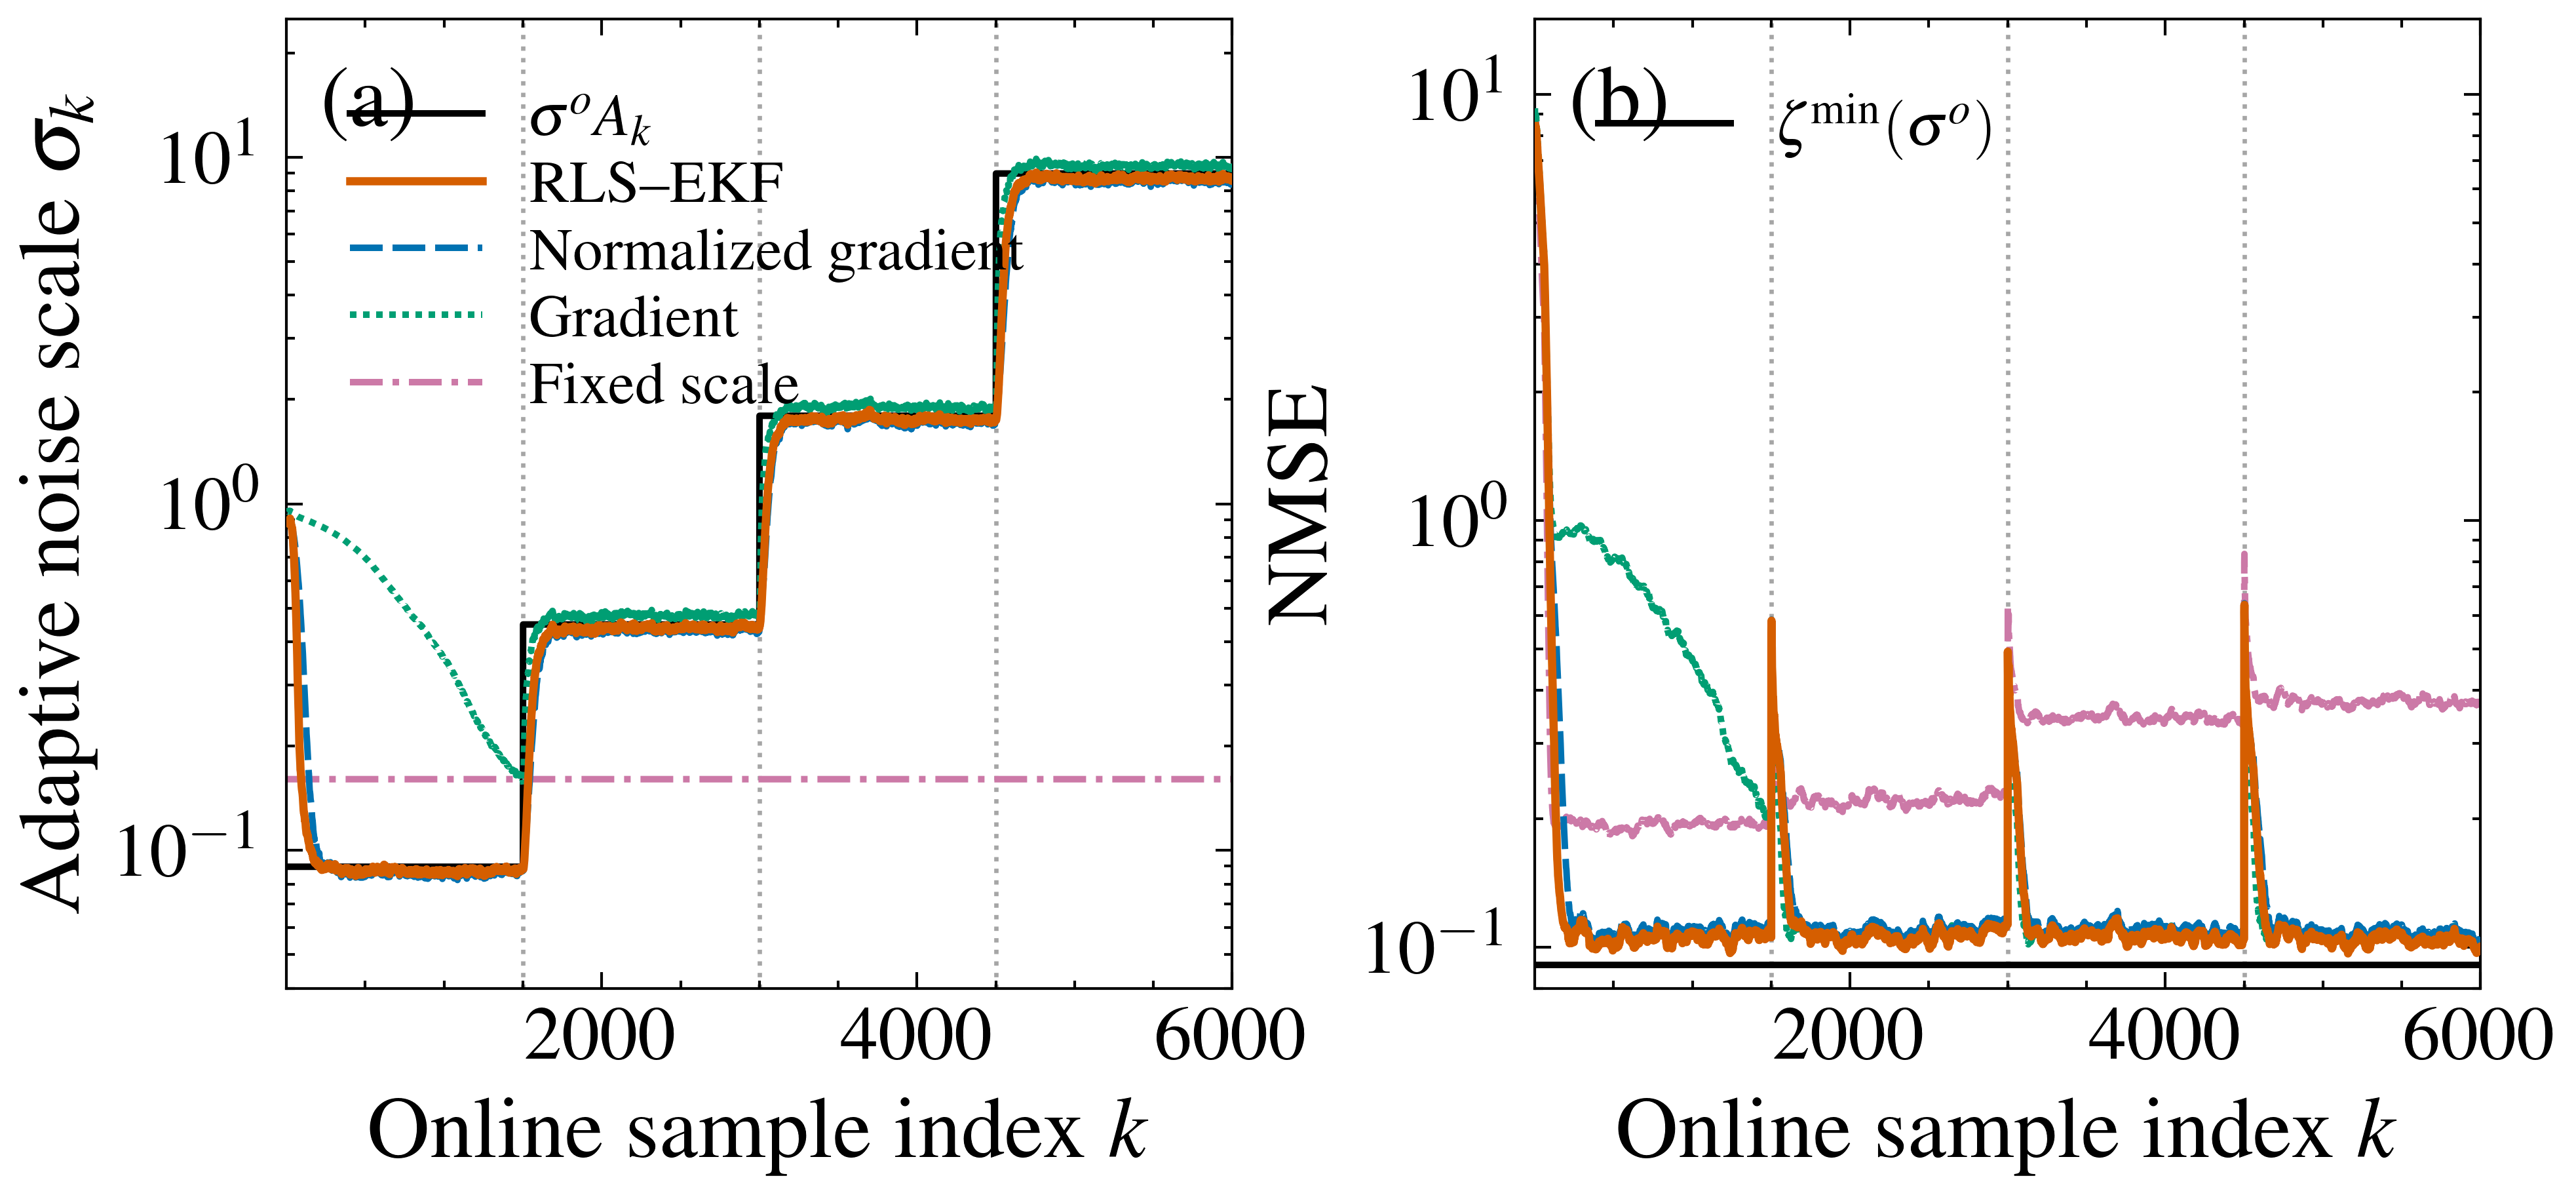

In [15]:
# ============================================================
# Cell 11. Fig. 3: Multi-step amplitude tracking 
#          (Gaussian Input, Uniform Dither, True Optimal Params)
# ============================================================
import os
import math
import numpy as np
import torch
import matplotlib
import matplotlib.pyplot as plt

try:
    import scienceplots
    plt.style.use(["science", "ieee"])
    matplotlib.rcParams.update({
        "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
        "mathtext.fontset": "stix", "font.size": 14,
        "axes.titlesize": 16, "axes.labelsize": 16, 
        "xtick.labelsize": 14, "ytick.labelsize": 14, 
        "legend.fontsize": 11, "axes.unicode_minus": False,
        "ps.fonttype": 42, "pdf.fonttype": 42
    })
except ImportError:
    matplotlib.rcParams.update({
        "font.family": "serif", "mathtext.fontset": "stix", 
        "font.size": 14, "axes.labelsize": 16,
        "axes.unicode_minus": False,
    })

# ---- 1. 理论参考值 (高斯输入 + 均布抖动) ----
LAW_G = law_gaussian()
TH_C, NS_C = (0.0,), (N_EL,)
REF_G = reference(LAW_G, TH_C, NS_C)
# 这里的 sigma^o 约为 0.897，与信号包络 1.0 完美错开！

# ---- 2. 构造多级连续跳变的幅度包络 (0.1 -> 0.5 -> 2.0 -> 10.0) ----
WARMUP_C = 1500
STEP_AMPS = (0.1, 0.5, 2.0, 10.0)
SEG_LEN = 1500
K_ONLINE = len(STEP_AMPS) * SEG_LEN
K_TOTAL = WARMUP_C + K_ONLINE

A_full = np.ones(K_TOTAL, dtype=np.float64)
seg_bounds_online = []
for idx, amp in enumerate(STEP_AMPS):
    sa = WARMUP_C + idx * SEG_LEN
    sb = sa + SEG_LEN
    A_full[sa:sb] = amp
    seg_bounds_online.append((idx * SEG_LEN, (idx + 1) * SEG_LEN))

# 生成高斯信号和 均布量化噪声 (在 Cell 5 中已修改)
rngs_c = child_rngs(tag=55, n=TRIALS)
z_full = np.stack([r.standard_normal(K_TOTAL) for r in rngs_c])
# 调用 Cell 5 重构的均布分布噪声生成
xi_full = np.stack([r.uniform(-math.sqrt(3.0), math.sqrt(3.0), (K_TOTAL, N_EL)).astype(np.float32) for r in rngs_c])
x_full = z_full * A_full[None, :]
xi_full_t = dither_to_device(xi_full)

# ---- 3. 直接代入你花费 1 小时网格搜索得到的 真实最优参数 ----
CONFIGS_C = [
    ("RLS--EKF",            dict(rule="ekf",   sigma0=1.0,       lam_f=0.93, q=0.01)),
    ("Normalized gradient", dict(rule="ngrad", sigma0=1.0,       lam_f=0.93, mu=0.1)),
    ("Gradient",            dict(rule="grad",  sigma0=1.0,       lam_f=0.93, mu=0.31623)),
    ("Fixed scale",         dict(rule="fixed", sigma0=0.16048,   lam_f=0.93)),
]

STYLES_C = {
    "RLS--EKF":            dict(color="#D55E00", ls="-",                  lw=1.5, zorder=5),
    "Normalized gradient": dict(color="#0072B2", ls=(0, (5, 1.5)),        lw=1.2, zorder=4),
    "Gradient":            dict(color="#009E73", ls=(0, (1, 1)),          lw=1.2, zorder=3),
    "Fixed scale":         dict(color="#CC79A7", ls=(0, (5, 1.5, 1, 1.5)),lw=1.2, zorder=2),
}

def segment_smooth(arr, bounds, win=60):
    """分段因果滑动平均，避免平滑失真"""
    out = np.empty_like(arr)
    for sa, sb in bounds:
        seg = arr[sa:sb]
        csum = np.cumsum(np.insert(seg, 0, 0.0))
        idx = np.arange(1, seg.size + 1)
        left = np.maximum(0, idx - win)
        out[sa:sb] = (csum[idx] - csum[left]) / (idx - left)
    return out

sigma_mean_c = {}
nmse_smooth_c = {}
A_online = A_full[WARMUP_C:]

# 遍历方法并运行真实仿真
print("Running final simulations with optimal parameters...")
for name, kw in CONFIGS_C:
    res_c = simulate(x_full, xi_full_t, TH_C, NS_C, rec_err=True, rec_sigma=True, **kw)
    sig_on = res_c["sigma"][:, WARMUP_C:]
    err_on = res_c["err"][:, WARMUP_C:]
    
    sigma_mean_c[name] = sig_on.mean(axis=0)
    inst_nmse = (err_on ** 2).mean(axis=0) / (A_online ** 2)
    nmse_smooth_c[name] = segment_smooth(inst_nmse, seg_bounds_online, win=60)

del xi_full_t, xi_full

# ---- 4. 绘制双子图 (Fig. 3) ----
kk_on = np.arange(1, K_ONLINE + 1)
fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(7.2, 3.2))
plt.subplots_adjust(wspace=0.32)

# -------- 左图 (a): 噪声尺度 sigma_k 追踪轨迹 --------
ax_a.plot(kk_on, REF_G["sigma_o"] * A_online, color="k", lw=1.2, zorder=1, label=r"$\sigma^o A_k$")
for name, _ in CONFIGS_C:
    ax_a.plot(kk_on, sigma_mean_c[name], label=name, **STYLES_C[name])

for boundary in (1500, 3000, 4500):
    ax_a.axvline(boundary, color="0.65", ls=":", lw=0.8, zorder=0)

ax_a.set_yscale("log")
ax_a.set(xlim=(1, K_ONLINE), ylim=(0.04, 25.0))
ax_a.set_xlabel(r"Online sample index $k$")
ax_a.set_ylabel(r"Adaptive noise scale $\sigma_k$")
ax_a.legend(loc="upper left", bbox_to_anchor=(0.01, 0.98), frameon=False, handlelength=2.2, labelspacing=0.2)

# -------- 右图 (b): 分段平滑后的归一化均方误差 NMSE --------
ax_b.axhline(REF_G["zeta_o"], color="k", lw=1.2, zorder=1, label=r"$\zeta^{\min}(\sigma^o)$")
for name, _ in CONFIGS_C:
    ax_b.plot(kk_on, nmse_smooth_c[name], **STYLES_C[name])

for boundary in (1500, 3000, 4500):
    ax_b.axvline(boundary, color="0.65", ls=":", lw=0.8, zorder=0)

ax_b.set_yscale("log")
ax_b.set(xlim=(1, K_ONLINE), ylim=(0.08, 15.0))
ax_b.set_xlabel(r"Online sample index $k$")
ax_b.set_ylabel(r"$\mathrm{NMSE}$")
ax_b.legend(loc="upper left", bbox_to_anchor=(0.01, 0.98), frameon=False, handlelength=2.2, labelspacing=0.2)

# -------- 统一设置序号与刻度 --------
for ax, lab in zip((ax_a, ax_b), "ab"):
    ax.text(0.04, 0.95, f"({lab})", transform=ax.transAxes, fontsize=16, va="top", ha="left", bbox=dict(facecolor="white", edgecolor="none", pad=1.2))
    ax.tick_params(direction="in", which="both", top=True, right=True, width=0.5)

OUT_DIR = r"D:\IEEE 2025 Adaptive weighted SSR"
os.makedirs(OUT_DIR, exist_ok=True)
for ext, kw in (("pdf", {}), ("eps", {}), ("png", {"dpi": 1000})):
    fig.savefig(os.path.join(OUT_DIR, f"FigSPL3u.{ext}"), bbox_inches="tight", **kw)
print(f"Plot saved successfully to {OUT_DIR}")
plt.show()